# Neuroworkshop — local setup

This notebook uses **YASA**. Download the complete repository, extract it,
and open **Neuroworkshop_github_final** as a folder in VS Code. Install Python 3.12
and the VS Code **Python** and **Jupyter** extensions before the workshop.
On macOS, if LightGBM reports a missing `libomp.dylib`, follow the [LightGBM installation guide](https://lightgbm.readthedocs.io/en/stable/Installation-Guide.html); with Homebrew, install `libomp` before starting the notebook. Run these commands **once**, in a terminal at the repository root:

**macOS / Linux**
```bash
python3.12 -m venv .venv-yasa
.venv-yasa/bin/python -m pip install -r requirements-yasa.txt
```

**Windows PowerShell**
```powershell
py -3.12 -m venv .venv-yasa
.\.venv-yasa\Scripts\python.exe -m pip install -r requirements-yasa.txt
```

In this notebook, click **Select Kernel → Python Environments → .venv-yasa**.
The terminal and notebook select Python independently. Restart the kernel after
switching, then run the cells from the beginning with **Shift+Enter**.
Notebooks 01–03 use `.venv-yasa`; notebook 04 uses `.venv-gssc`.

Internet access is needed for package installation and the first public sample
download. Later runs reuse the local `data/` cache. Results are generated in
`outputs/`. CPU is sufficient. Installation is preparation, outside the lesson.
Virtual environments in the facilitator's local folder are machine-specific;
attendees create their own from the requirements above.


## What you will learn

* Locate a trough, positive peak and zero crossing in filtered EEG.
* Read peak-to-peak amplitude, duration and slope.
* Select an explicitly defined slow-oscillation subset.

In [1]:
import importlib.util
import subprocess
import sys

try:
    import google.colab
    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "yasa==0.8.1", "ipywidgets>=8,<9",
    ])
    from google.colab import output
    output.enable_custom_widget_manager()
else:
    print("Local mode: select .venv-yasa as the notebook kernel.")

Local mode: select .venv-yasa as the notebook kernel.


In [2]:
import ctypes
import importlib.metadata as metadata
import json
import os
from pathlib import Path

# Find the downloaded repository from its root or notebooks folder.
if IN_COLAB:
    ROOT = Path.cwd() / "Neuroworkshop_github_final"
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates if (p / "requirements-yasa.txt").is_file()
                 and (p / "requirements-gssc.txt").is_file()), None)
    if ROOT is None:
        raise RuntimeError("Open the complete Neuroworkshop_github_final folder in VS Code, including its requirements files.")
ROOT.mkdir(parents=True, exist_ok=True)
for variable, folder in {"YASA_DATA_DIR": "data", "MPLCONFIGDIR": ".mplconfig", "NUMBA_CACHE_DIR": ".numba-cache"}.items():
    (ROOT / folder).mkdir(exist_ok=True)
    os.environ.setdefault(variable, str(ROOT / folder))

# A prepared local environment can carry its own macOS OpenMP runtime.
omp = Path(sys.prefix) / "lib" / "libomp.dylib"
if sys.platform == "darwin" and omp.is_file():
    ctypes.CDLL(str(omp), mode=ctypes.RTLD_GLOBAL)

import ipywidgets as widgets
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import yasa
from IPython.display import display
from mne.filter import filter_data

plt.rcParams.update({"figure.figsize": (11, 3), "figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
mne.set_log_level("ERROR")
assert yasa.__version__ == "0.8.1", "Select the prepared YASA 0.8.1 workshop environment."
OUT = ROOT / "outputs" / "three_notebook_workshop" / "05_sw_detection"
OUT.mkdir(parents=True, exist_ok=True)
versions = {name: metadata.version(name) for name in ["yasa", "mne", "numpy", "pandas", "scipy", "ipywidgets"]}
(OUT / "versions.json").write_text(json.dumps(versions, indent=2))
print("Python:", sys.executable)
print("YASA:", yasa.__version__, "| Results:", OUT)

Python: <repository>/.venv-yasa/bin/python
YASA: 0.8.1 | Results: /private<repository>/outputs/three_notebook_workshop/05_sw_detection


## 1. Look at a slow wave before detecting it

A **slow wave** is a slow fluctuation in the scalp EEG. We will measure its
negative trough, following positive peak, duration and slope. These quantities
refer to a filtered signal and depend on the recording channel and reference.

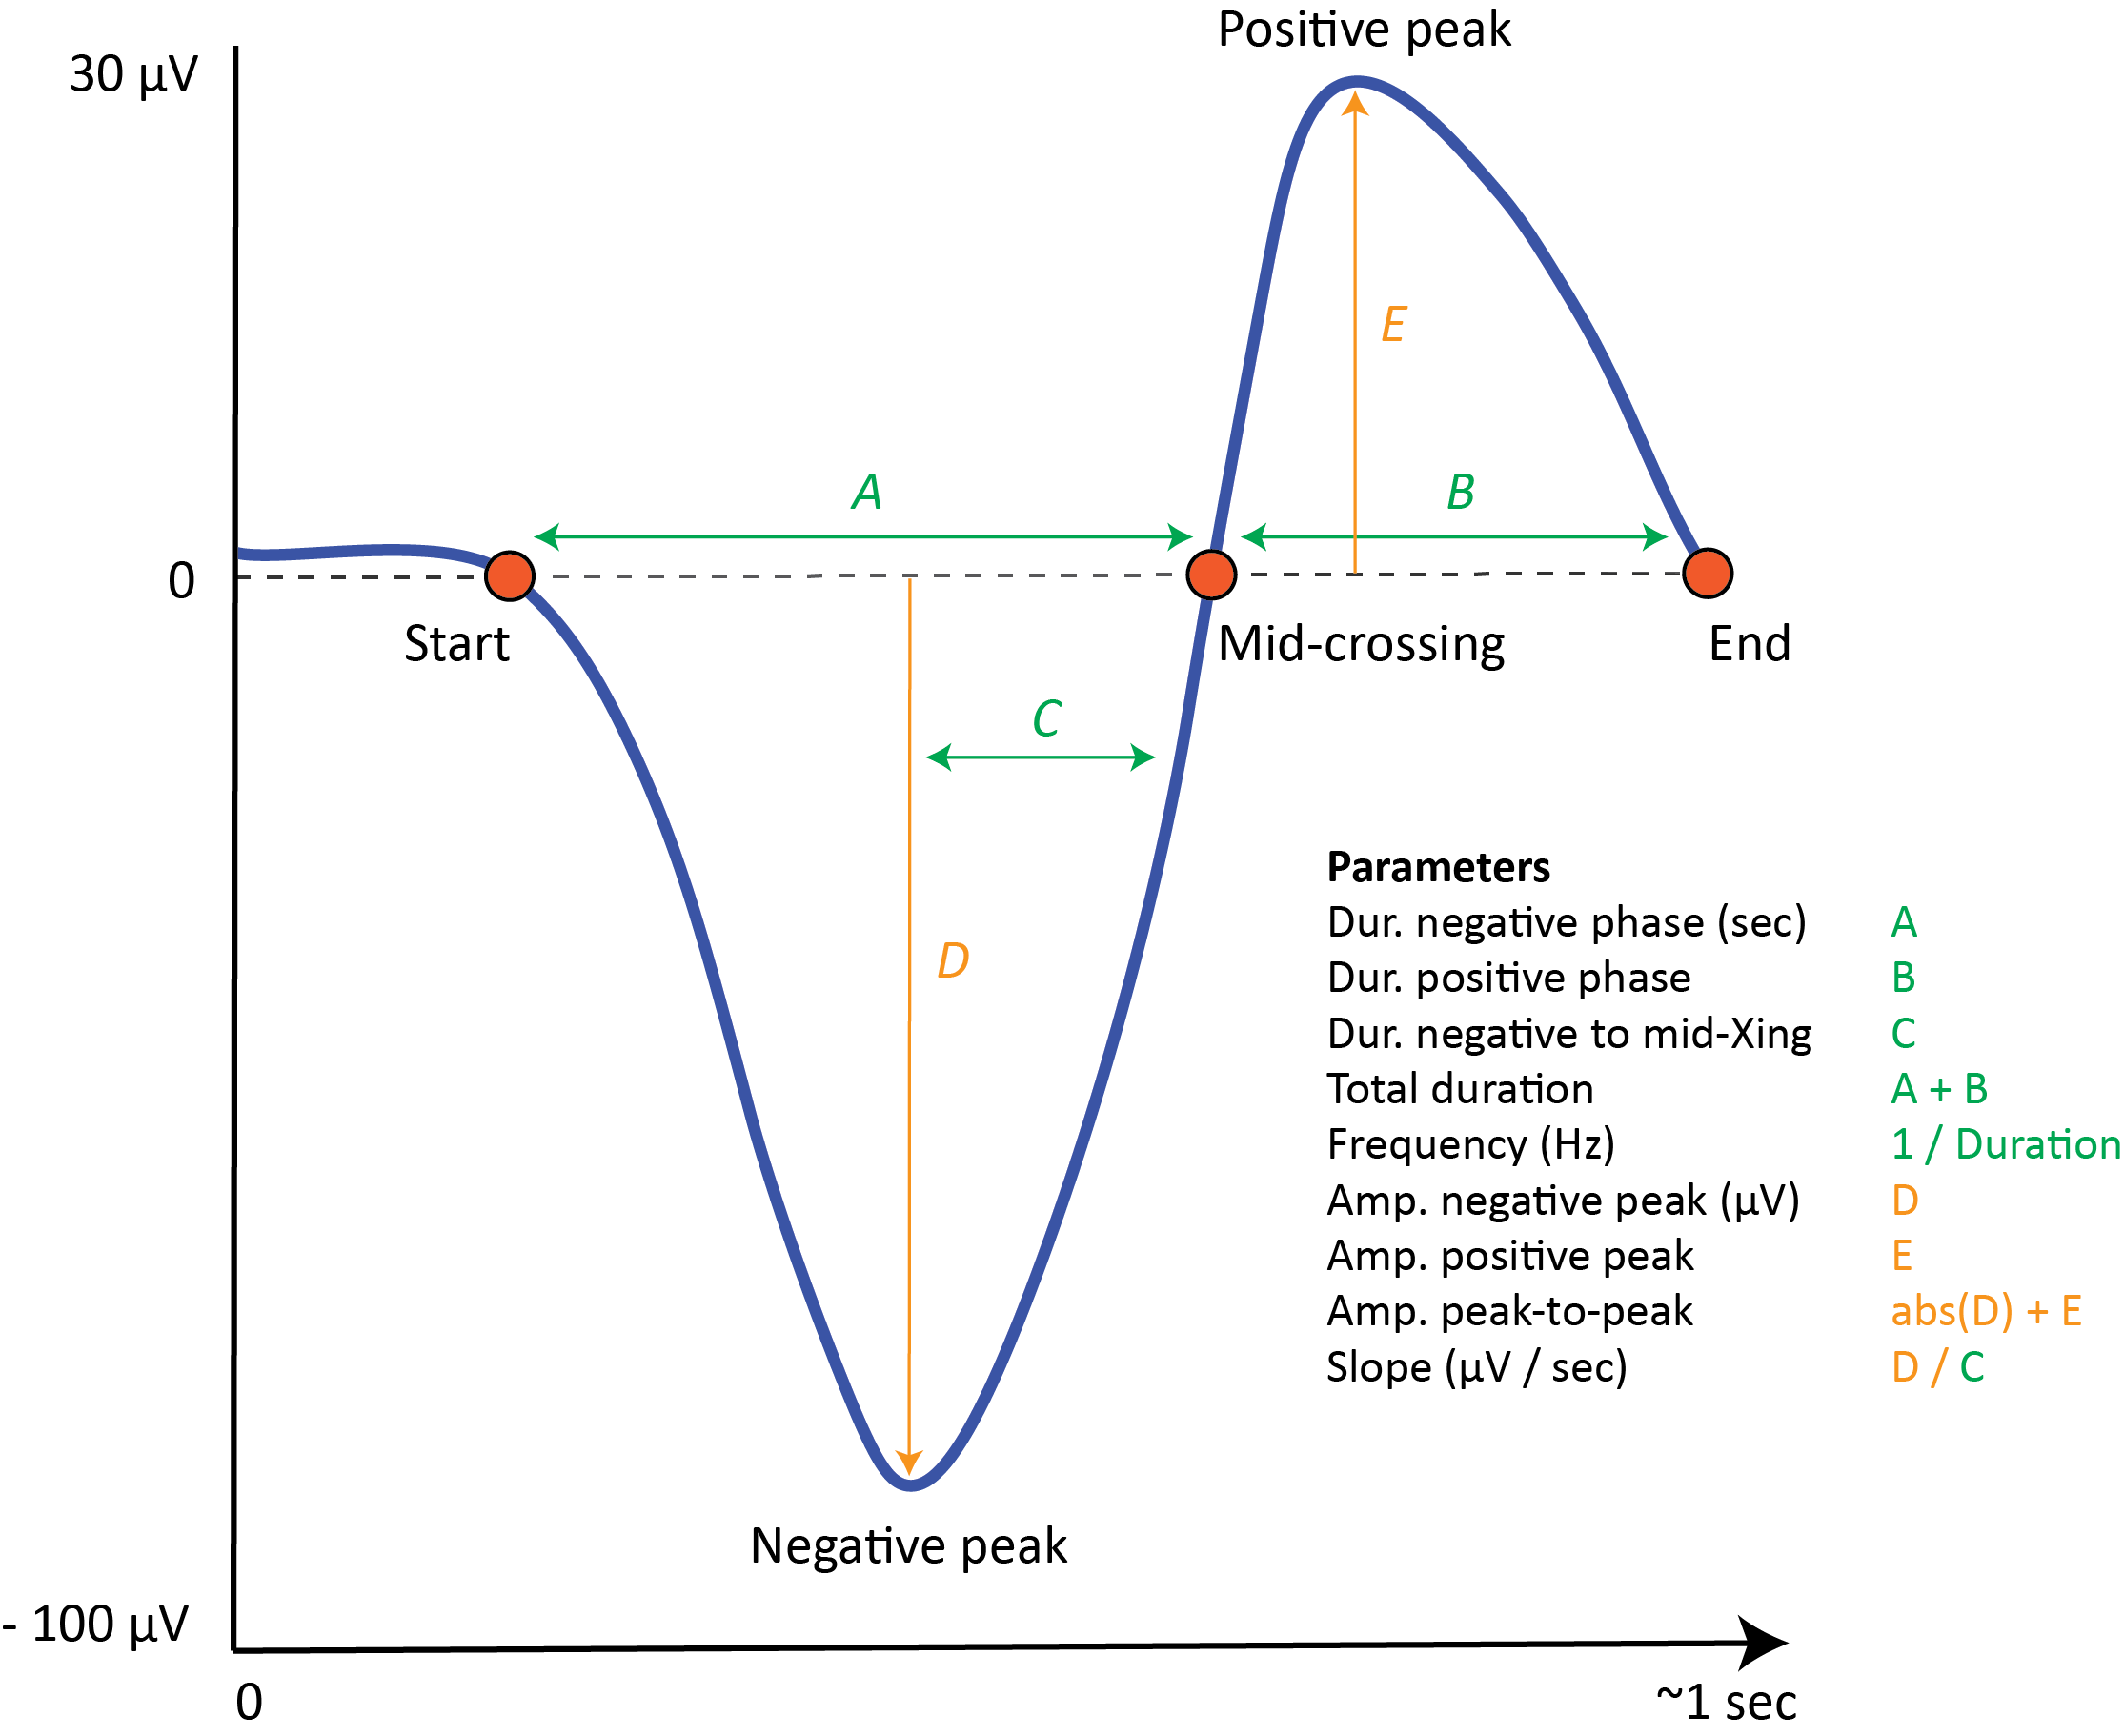

We use the original notebook 05 example: **30 seconds of Fz during N3**, sampled
at **100 Hz**. NumPy EEG values are in **µV**. The detector receives 30 additional
seconds on each side; we keep only events entirely inside the central window.
This reduces filtering problems at the boundaries of the displayed excerpt.

Display: 30 s of Fz; detector input: 90 s.
Central-window sleep stages: [3]


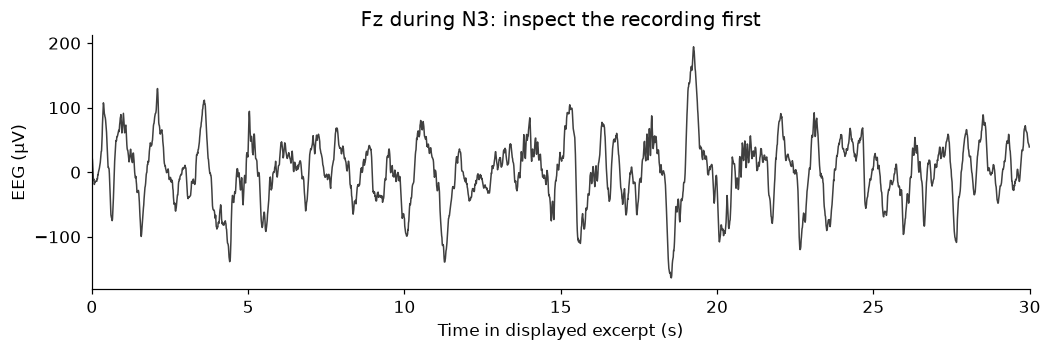

In [3]:
eeg_path = yasa.fetch_sample("full_6hrs_100Hz_Cz+Fz+Pz.npz")
hypno_path = yasa.fetch_sample("full_6hrs_100Hz_hypno.npz")

sf = 100.0
context_start, context_end = 666000, 675000
central_start, central_end = 669000, 672000
with np.load(eeg_path, allow_pickle=False) as sample:
    # Original sample channel order: Cz, Fz, Pz. Index 1 is Fz.
    data_context = sample["data"][1, context_start:context_end].astype(float)
with np.load(hypno_path, allow_pickle=False) as sample:
    hypno_context = sample["hypno"].ravel()[context_start:context_end].astype(int)

offset = int((central_start - context_start))
central_samples = central_end - central_start
data = data_context[offset:offset + central_samples]
times = np.arange(data.size) / sf
assert data_context.size == hypno_context.size == 9000
assert data.size == 3000
print(f"Display: {data.size / sf:g} s of Fz; detector input: {data_context.size / sf:g} s.")
print("Central-window sleep stages:", np.unique(hypno_context[offset:offset + central_samples]))

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(times, data, color="0.25", linewidth=1)
ax.set(xlabel="Time in displayed excerpt (s)", ylabel="EEG (µV)",
       xlim=(0, 30), title="Fz during N3: inspect the recording first")
plt.show()

## 2. Detect broad slow waves

`sw_detect` applies amplitude and timing criteria to EEG filtered at **0.3–1.5 Hz**.
These defaults identify a set of **broad slow waves**; they do not establish a
universal definition of a slow oscillation (SO).

The code below uses the same frequency range and transition widths to produce
the filtered trace for our plots. This is why the reported peaks line up with
the **filtered** EEG. A peak may be displaced relative to the raw trace.

We limit detection to scored N2/N3. Times in the output below start at zero for
the **central 30-second excerpt**, rather than at the start of the six-hour file.

In [4]:
freq_sw = (0.3, 1.5)
sw = yasa.sw_detect(
    data_context, sf=sf, ch_names=["Fz"], hypno=hypno_context, include=(2, 3),
    freq_sw=freq_sw, dur_neg=(0.3, 1.5), dur_pos=(0.1, 1),
    amp_neg=(40, 200), amp_pos=(10, 150), amp_ptp=(75, 350),
    coupling=False, remove_outliers=False,
)
if sw is None:
    raise RuntimeError("No slow waves detected. Inspect the data and detector settings.")

context_events = sw.summary()
offset_seconds = offset / sf
window_seconds = central_samples / sf
sw_events = context_events.loc[
    (context_events["Start"] >= offset_seconds)
    & (context_events["End"] <= offset_seconds + window_seconds)
].copy().reset_index(drop=True)
time_columns = ["Start", "NegPeak", "MidCrossing", "PosPeak", "End"]
sw_events[time_columns] = sw_events[time_columns] - offset_seconds

filtered_context = filter_data(
    data_context, sf, *freq_sw, method="fir", l_trans_bandwidth=0.2,
    h_trans_bandwidth=0.2, verbose=False,
)
data_filtered = filtered_context[offset:offset + central_samples]
print(f"Broad slow waves wholly inside the displayed window: {len(sw_events)}")

Broad slow waves wholly inside the displayed window: 11


**Plot helper:** run this cell once. It keeps the same 30-second raw and filtered
traces on screen while changing which events are highlighted. 

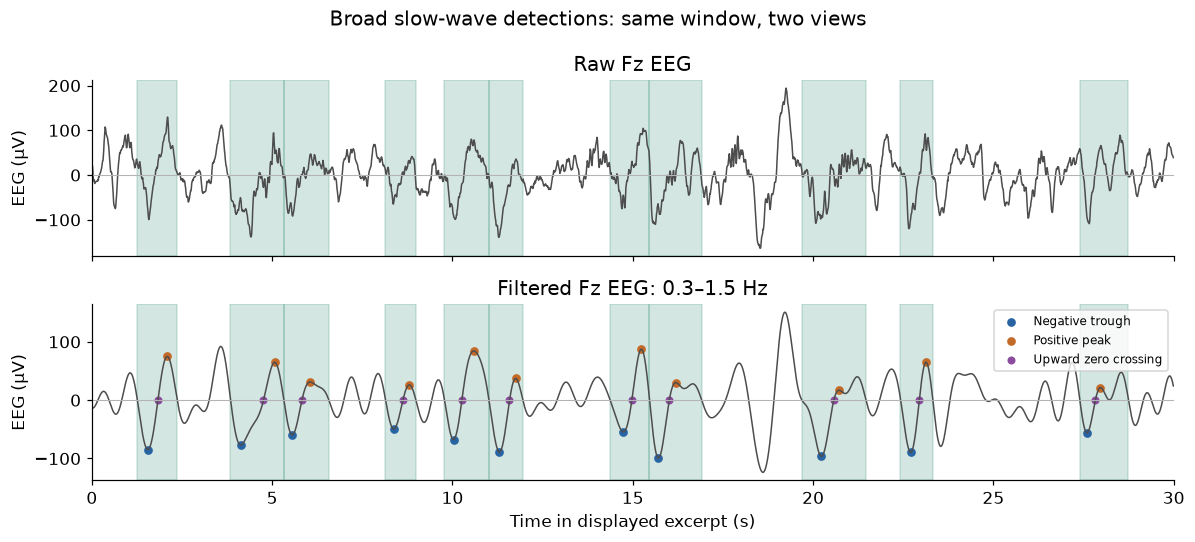

In [5]:
def plot_slow_waves(events, title):
    fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
    for ax, signal, label in zip(
        axes, [data, data_filtered], ["Raw Fz EEG", "Filtered Fz EEG: 0.3–1.5 Hz"]
    ):
        ax.plot(times, signal, color="0.3", linewidth=1)
        for event in events.itertuples():
            ax.axvspan(event.Start, event.End, color="#23856D", alpha=0.2)
        ax.set(ylabel="EEG (µV)", title=label, xlim=(0, 30))
        ax.axhline(0, color="0.7", linewidth=0.7)
    if not events.empty:
        axes[1].scatter(events["NegPeak"], events["ValNegPeak"],
                        color="#2863A3", s=22, label="Negative trough")
        axes[1].scatter(events["PosPeak"], events["ValPosPeak"],
                        color="#C46A28", s=22, label="Positive peak")
        axes[1].scatter(events["MidCrossing"], np.zeros(len(events)),
                        color="#8B4C9F", s=18, label="Upward zero crossing")
        axes[1].legend(loc="upper right", fontsize=8)
    axes[1].set_xlabel("Time in displayed excerpt (s)")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_slow_waves(sw_events, "Broad slow-wave detections: same window, two views")

## 3. Read the measurements

| Column | Meaning | Unit |
|---|---|---|
| `PTP` | Positive peak minus negative trough, measured on filtered EEG | µV |
| `Duration` | Full detected cycle from `Start` to `End` | s |
| `Frequency` | Inverse of full-cycle duration: `1 / Duration` | Hz |
| `Slope` | Rise from negative trough to the upward zero crossing | µV/s |
| `Stage` | Reference sleep stage where the event occurred | 2 = N2; 3 = N3 |

For this detector, slope is the absolute negative-trough amplitude divided by
the time from that trough to `MidCrossing`. A larger amplitude and a faster rise
can both produce a larger slope. This is a scalp-wave measurement.

In [6]:
measurement_columns = ["Start", "NegPeak", "PosPeak", "PTP", "Duration", "Frequency", "Slope", "Stage"]
display(sw_events[measurement_columns].round(2))

,Start,NegPeak,PosPeak,PTP,Duration,Frequency,Slope,Stage
0,1.26,1.55,2.09,159.49,1.10,0.91,302.13,3
1,3.84,4.13,5.07,141.59,1.48,0.68,124.01,3
2,5.32,5.56,6.05,90.41,1.25,0.80,228.15,3
3,8.14,8.37,8.80,75.71,0.84,1.19,197.97,3
4,9.77,10.03,10.59,151.85,1.24,0.81,293.42,3
5,11.01,11.30,11.75,125.95,0.94,1.06,317.17,3
6,14.37,14.74,15.24,141.51,1.09,0.92,236.44,3
7,15.46,15.71,16.19,129.41,1.45,0.69,330.94,3
8,19.68,20.23,20.72,113.09,1.78,0.56,282.77,3
9,22.42,22.71,23.13,154.26,0.90,1.11,388.71,3


## 4. Define an SO subset and test a prediction

For this workshop, **SO candidates** are the detected slow waves with full-cycle
durations from **1 to 2 seconds**. This is an explicit teaching definition,
corresponding to 0.5–1 Hz by `1 / Duration`; it is not a universal SO criterion.
All the preceding amplitude and phase-duration criteria still apply.

**Predict before running:** if the minimum duration increases from **1.0 to
1.5 seconds**, will the number of selected candidates increase, decrease or
stay unchanged? Explain why, then change the parameter and rerun the next cell.

The raw trace, filtered trace, window and broad detections stay fixed. Only the
selection criterion changes. Each function call returns a table of candidates.

In [7]:
def select_so(min_duration=1.0):
    min_duration = float(min_duration)
    if not 1.0 <= min_duration <= 2.0:
        raise ValueError("Choose a minimum full-cycle duration from 1.0 to 2.0 seconds.")
    selected = sw_events.loc[
        sw_events["Duration"].between(min_duration, 2.0, inclusive="both")
    ].copy()
    print(f"SO candidates: {len(selected)} of {len(sw_events)} broad slow waves.")
    print(f"Selection: full-cycle duration {min_duration:.1f}–2.0 s; all other criteria unchanged.")
    plot_slow_waves(selected, f"SO candidates with full cycles of {min_duration:.1f}–2.0 s")
    return selected

SO candidates: 8 of 11 broad slow waves.
Selection: full-cycle duration 1.0–2.0 s; all other criteria unchanged.


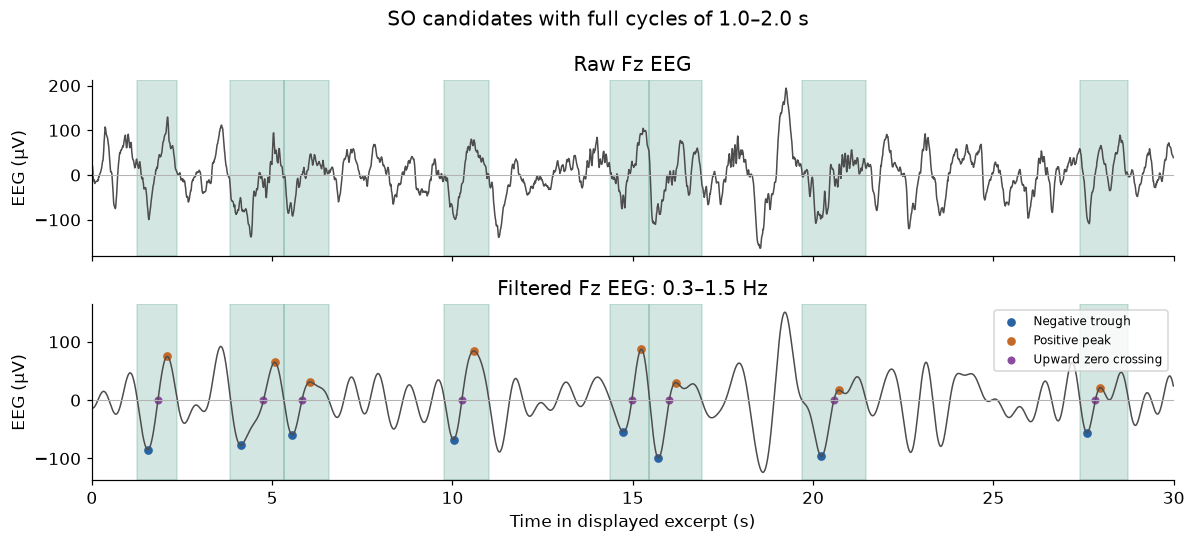

,Start,NegPeak,PosPeak,PTP,Duration,Frequency,Slope,Stage
0,1.26,1.55,2.09,159.49,1.10,0.91,302.13,3
1,3.84,4.13,5.07,141.59,1.48,0.68,124.01,3
2,5.32,5.56,6.05,90.41,1.25,0.80,228.15,3
4,9.77,10.03,10.59,151.85,1.24,0.81,293.42,3
6,14.37,14.74,15.24,141.51,1.09,0.92,236.44,3
7,15.46,15.71,16.19,129.41,1.45,0.69,330.94,3
8,19.68,20.23,20.72,113.09,1.78,0.56,282.77,3
10,27.39,27.60,27.97,77.45,1.35,0.74,253.81,3


In [8]:
minimum_so_duration = 1.0
so_events = select_so(minimum_so_duration)
display(so_events[measurement_columns].round(2))

### Optional: explore with a slider

Move the slider, then click **Explore duration criterion**. The button does not
run until you click it. If widgets are unavailable, call `select_so(1.5)` directly.
To save a new configuration, change `minimum_so_duration` in the parameter cell
above, then rerun that cell and the save cell below.

In [9]:
so_duration_slider = widgets.FloatSlider(
    value=1.0, min=1.0, max=1.8, step=0.1, description="Minimum (s)",
    continuous_update=False, style={"description_width": "initial"},
)
so_explore_button = widgets.Button(description="Explore duration criterion")
so_explore_output = widgets.Output()


def explore_so_duration(_):
    with so_explore_output:
        so_explore_output.clear_output(wait=True)
        preview = select_so(so_duration_slider.value)
        display(preview[measurement_columns].round(2))


so_explore_button.on_click(explore_so_duration)
display(widgets.VBox([so_duration_slider, so_explore_button, so_explore_output]))

## 5. Save a reproducible result

The saved tables include both broad slow waves and the SO subset chosen in the
parameter cell. Event times are relative to the central excerpt. A JSON file
records the original sample indices, filtering, detector thresholds and subset
definition so the selection can be reconstructed.

In [10]:
sw_events.to_csv(OUT / "slow_waves_Fz_central30s.csv", index=False)
so_events.to_csv(OUT / "SO_candidates_Fz_central30s.csv", index=False)
slow_wave_parameters = {
    "source_notebook": "05_sw_detection.ipynb",
    "yasa_version": yasa.__version__,
    "eeg_sample": eeg_path.name,
    "hypnogram_sample": hypno_path.name,
    "channel": "Fz", "data_unit": "microvolts", "sampling_rate_Hz": sf,
    "context_indices_start_inclusive_end_exclusive": [context_start, context_end],
    "central_indices_start_inclusive_end_exclusive": [central_start, central_end],
    "context_duration_s": data_context.size / sf,
    "central_duration_s": central_samples / sf,
    "event_time_origin_s_from_recording_start": central_start / sf,
    "keep_events": "Start >= 30 s and End <= 60 s in context, then subtract 30 s",
    "frequency_band_Hz": list(freq_sw), "filter_transition_bandwidth_Hz": 0.2,
    "included_reference_stages": [2, 3],
    "negative_phase_duration_s": [0.3, 1.5], "positive_phase_duration_s": [0.1, 1.0],
    "negative_peak_amplitude_uV": [40, 200], "positive_peak_amplitude_uV": [10, 150],
    "peak_to_peak_amplitude_uV": [75, 350], "coupling": False,
    "remove_outliers": False,
    "SO_subset": {
        "definition": "Teacher-defined subset of broad slow waves by full-cycle duration",
        "minimum_duration_s": minimum_so_duration, "maximum_duration_s": 2.0,
        "inclusive_bounds": True,
    },
}
(OUT / "slow_wave_parameters.json").write_text(json.dumps(slow_wave_parameters, indent=2))
print("Saved broad-wave events, SO candidates and parameters in:", OUT)

Saved broad-wave events, SO candidates and parameters in: /private<repository>/outputs/three_notebook_workshop/05_sw_detection


## Takeaways

* Detection criteria define which waves enter the table; they are part of the
  scientific measurement, not just software settings.
* Amplitude, duration and slope describe different aspects of the same wave.
  Peaks and slope are measured on filtered EEG.


These notebooks use **different recordings**. We cannot combine a spindle time
from notebook 01 with an SO time here to measure SO–spindle coupling. That
requires events from an aligned recording and a specified channel/phase
convention. Estimating SO phase offline also does not establish accurate
phase-triggered stimulation.

## Sources and attribution

YASA: Raphael Vallat, Remington Mallett and contributors; BSD 3-Clause licence
(full license notice below). Sample data: [YASA dataset v1](https://zenodo.org/records/14564285).

## Upstream software license notice

YASA retains its upstream license. The notice is reproduced here so this notebook does not depend on a separate license file.

```text
BSD 3-Clause License

Copyright (c) 2018, Raphael Vallat
All rights reserved.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

1. Redistributions of source code must retain the above copyright notice, this
   list of conditions and the following disclaimer.

2. Redistributions in binary form must reproduce the above copyright notice,
   this list of conditions and the following disclaimer in the documentation
   and/or other materials provided with the distribution.

3. Neither the name of the copyright holder nor the names of its
   contributors may be used to endorse or promote products derived from
   this software without specific prior written permission.

THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS AND CONTRIBUTORS "AS IS"
AND ANY EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR PURPOSE ARE
DISCLAIMED. IN NO EVENT SHALL THE COPYRIGHT HOLDER OR CONTRIBUTORS BE LIABLE
FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL, EXEMPLARY, OR CONSEQUENTIAL
DAMAGES (INCLUDING, BUT NOT LIMITED TO, PROCUREMENT OF SUBSTITUTE GOODS OR
SERVICES; LOSS OF USE, DATA, OR PROFITS; OR BUSINESS INTERRUPTION) HOWEVER
CAUSED AND ON ANY THEORY OF LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY,
OR TORT (INCLUDING NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE
OF THIS SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
```